# TRỤ CỘT 1: ĐỘ HOÀN THIỆN (MISSING VALUE PROFILING)

📊 Bảng thống kê khuyết thiếu — Tầng Raw Payload (Đã làm phẳng general_info):


,Layer,Missing_Count,Missing_Percentage (%)
general_info.hiring_quantity,Raw Payload,677,44.54
salary_raw,Raw Payload,504,33.16
working_time,Raw Payload,462,30.39
benefits_bullets,Raw Payload,77,5.07
requirements_bullets,Raw Payload,69,4.54
description_bullets,Raw Payload,65,4.28
company_field,Raw Payload,31,2.04
company_address,Raw Payload,20,1.32
location,Raw Payload,9,0.59
general_info.employment_type,Raw Payload,8,0.53



📊 Bảng thống kê khuyết thiếu — Tầng Metadata (Vận hành & Hash):


,Layer,Missing_Count,Missing_Percentage (%)


🖼️  Đã lưu reports\figures\jobsgo\01_jobsgo_data_completeness_bar_all.png (DPI 300)


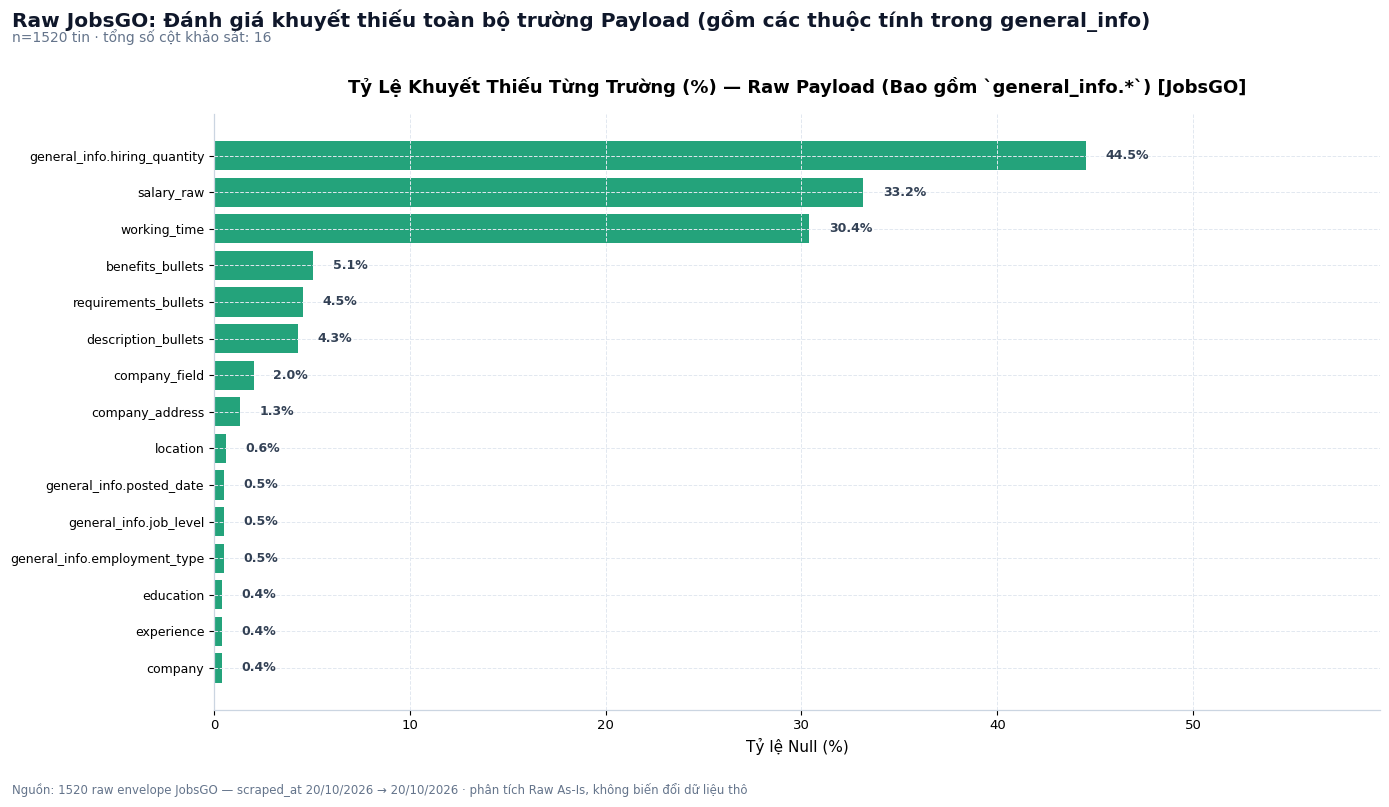

In [52]:
# ==========================================
# LÀM SẠCH NULL ẨN & TRỰC QUAN HÓA TỶ LỆ KHUYẾT THIẾU — METADATA & RAW PAYLOAD (JOBSGO)
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def clean_hidden_nulls_jobsgo(df):
    """
    Nhận diện và chuyển đổi các giá trị khuyết thiếu dạng text, placeholder, 
    hoặc mảng/dict rỗng về chuẩn np.nan dành riêng cho JobsGO.
    """
    df_cleaned = df.copy()
    
    global MARKERS
    if 'MARKERS' not in globals():
        MARKERS = [
            "", " ", "nan", "none", "null", "n/a", "na", "[]", "{}", "-", "…", "...",
            "chưa cập nhật", "chưa có", "không xác định", "thoả thuận", "thỏa thuận",
            "thoa thuan", "cạnh tranh", "competitive", "nego", "negotiable", 
            "đăng nhập để xem mức lương", "đang cập nhật"
        ]
    
    # 1. Xử lý các cột object/chuỗi (loại bỏ null trá hình)
    for col in df_cleaned.select_dtypes(include=['object']):
        df_cleaned[col] = df_cleaned[col].apply(
            lambda x: np.nan if (isinstance(x, str) and (not x.strip() or x.strip().lower() in MARKERS)) else x
        )
    
    # 2. Xử lý các list/dict/tuple rỗng trên toàn bộ dataframe
    df_cleaned = df_cleaned.map(
        lambda x: np.nan if isinstance(x, (list, dict, tuple)) and len(x) == 0 else x
    )
    
    return df_cleaned

# ==========================================
# 1. CHUẨN HÓA & LÀM PHẲNG DỮ LIỆU PAYLOAD (Bao gồm các trường trong general_info)
# ==========================================
if 'df_top' in globals():
    # Sử dụng pd.json_normalize để đưa các trường lồng nhau như general_info.* ra các cột phẳng
    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)
else:
    raise ValueError("⚠️ Chưa khởi tạo `df_top` trong môi trường làm việc!")

# Làm sạch null ẩn cho Raw Payload đã làm phẳng
df_top_cleaned = clean_hidden_nulls_jobsgo(df_top_flat)

# Làm sạch null ẩn cho Metadata nếu tồn tại
if 'df_meta' in globals():
    df_meta_cleaned = clean_hidden_nulls_jobsgo(df_meta)
else:
    df_meta_cleaned = None

# ==========================================
# 2. THỐNG KÊ CHI TIẾT KHUYẾT THIẾU (CẢ 2 TẦNG)
# ==========================================
def missing_value_summary_detailed(df, layer_name="Payload"):
    missing_counts = df.isnull().sum()
    missing_percentages = (missing_counts / len(df)) * 100
    summary_df = pd.DataFrame({
        'Layer': layer_name,
        'Missing_Count': missing_counts,
        'Missing_Percentage (%)': missing_percentages.round(2)
    }).sort_values(by='Missing_Percentage (%)', ascending=False)
    return summary_df[summary_df['Missing_Count'] > 0]

print("📊 Bảng thống kê khuyết thiếu — Tầng Raw Payload (Đã làm phẳng general_info):")
payload_summary = missing_value_summary_detailed(df_top_cleaned, "Raw Payload")
show(payload_summary, limit=50)

if df_meta_cleaned is not None:
    print("\n📊 Bảng thống kê khuyết thiếu — Tầng Metadata (Vận hành & Hash):")
    meta_summary = missing_value_summary_detailed(df_meta_cleaned, "Metadata")
    show(meta_summary, limit=20)

# ==========================================
# 3. TRỰC QUAN HÓA: BAR CHART KHUYẾT THIẾU TỔNG HỢP PAYLOAD
# ==========================================
def plot_completeness_bar_payload(df_payload, save_filename):
    null_percentages = (df_payload.isnull().sum() / len(df_payload)) * 100
    cols_with_nulls = null_percentages[null_percentages > 0]
    
    if cols_with_nulls.empty:
        print("✅ Dữ liệu Payload hoàn hảo, không có cột nào bị khuyết thiếu!")
        return

    missing_pct_sorted = cols_with_nulls.sort_values(ascending=True)

    fig_height = max(8, len(missing_pct_sorted) * 0.38)
    fig, ax = plt.subplots(figsize=(14, fig_height))
    
    bar_color = PALETTE[1] if 'PALETTE' in globals() else '#059669'
    bars = ax.barh(missing_pct_sorted.index, missing_pct_sorted.values, color=bar_color, alpha=0.88)
    
    label_source = SOURCE_LABEL if 'SOURCE_LABEL' in globals() else 'JobsGO'
    ax.set_title(f"Tỷ Lệ Khuyết Thiếu Từng Trường (%) — Raw Payload (Bao gồm `general_info.*`) [{label_source}]", fontsize=13, pad=15, fontweight='bold')
    ax.set_xlabel("Tỷ lệ Null (%)", fontsize=11)
    ax.tick_params(axis='y', labelsize=9)
    
    # Mở rộng trục X để hiển thị rõ nhãn phần trăm
    ax.set_xlim(0, max(missing_pct_sorted.values) + 15) 
    
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 1, 
                bar.get_y() + bar.get_height()/2, 
                f'{width:.1f}%', 
                va='center', ha='left', fontsize=9, fontweight='bold', color="#334155")
    
    if 'finalize' in globals():
        finalize(fig, f"Raw {label_source}: Đánh giá khuyết thiếu toàn bộ trường Payload (gồm các thuộc tính trong general_info)",
                 f"n={len(df_payload)} tin · tổng số cột khảo sát: {len(df_payload.columns)}",
                 save_filename)
    else:
        save_path = os.path.join("reports", "figures", "jobsgo", save_filename)
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close()
        print(f"✅ Đã lưu biểu đồ tại: {save_path}")

# Gọi hàm vẽ và lưu file báo cáo tổng hợp
plot_completeness_bar_payload(df_top_cleaned, "01_jobsgo_data_completeness_bar_all.png")

# TRỤ CỘT 2: TÍNH HỢP LỆ VÀ KIỂU DỮ LIỆU

In [53]:
# ==========================================
# 1. HÀM CHẨN ĐOÁN CHUNG VỀ KIỂU DỮ LIỆU (DTYPES)
# ==========================================
def check_data_types(df, name="DataFrame"):
    """
    Kiểm tra kiểu dữ liệu thực tế của các cột và đối chiếu sơ bộ
    """
    print(f"\n--- 1. TỔNG QUAN KIỂU DỮ LIỆU ({name}) ---")
    if df is None or df.empty:
        print(f"⚠️ {name} trống hoặc không tồn tại.")
        return
    dtype_summary = pd.DataFrame(df.dtypes, columns=['Thực_tế_Dtype'])
    dtype_summary['Số_lượng_Non_Null'] = df.notnull().sum()
    dtype_summary['Ví_dụ_Giá_trị'] = df.apply(lambda x: x.dropna().iloc[0] if x.notna().any() else np.nan)
    
    display(dtype_summary)

# ==========================================
# 2. CHẨN ĐOÁN TẦNG METADATA (df_meta)
# ==========================================
def validate_metadata_layer(df_meta):
    """
    Kiểm tra tính toàn vẹn của metadata vận hành, mã băm (hash) và mốc thời gian cào
    """
    print("\n--- 2. CHẨN ĐOÁN TẦNG METADATA (VẬN HÀNH & HASH) ---")
    if df_meta is None or df_meta.empty:
        print("⚠️ df_meta trống hoặc không tồn tại.")
        return
    
    tech_cols = ['m_job_id', 'm_source_url', 'm_content_hash', 'm_canonical_hash', 'version', 'scraper_version']
    for col in tech_cols:
        if col in df_meta.columns:
            total = len(df_meta)
            unique_cnt = df_meta[col].nunique()
            null_cnt = df_meta[col].isnull().sum()
            print(f"  - [{col}]: {unique_cnt}/{total} giá trị độc lập, {null_cnt} bản ghi khuyết thiếu.")
        else:
            print(f"  - [{col}]: Không xuất hiện trong df_meta.")

    if 'm_scraped_at' in df_meta.columns:
        scraped_dt = pd.to_datetime(df_meta['m_scraped_at'], errors='coerce', utc=True)
        print(f"  - Mốc thời gian cào (m_scraped_at):")
        print(f"    + Sớm nhất: {scraped_dt.min()}")
        print(f"    + Muộn nhất: {scraped_dt.max()}")
        print(f"    + Số giá trị parse lỗi: {scraped_dt.isnull().sum()}")

# ==========================================
# 3. CHẨN ĐOÁN CÁC TRƯỜNG BÊN TRONG `general_info` (Payload)
# ==========================================
def validate_general_info_fields(df_top_flat):
    """
    Khảo sát chi tiết các trường cấu trúc bên trong general_info sau khi làm phẳng
    (employment_type, job_level, posted_date, hiring_quantity, v.v.)
    """
    print("\n--- 3. CHẨN ĐOÁN CÁC TRƯỜNG BÊN TRONG general_info ---")
    
    gi_cols = [c for c in df_top_flat.columns if c.startswith("general_info.")]
    if not gi_cols:
        print("⚠️ Không tìm thấy các trường `general_info.*` trong payload.")
        return

    print(f"   Tìm thấy {len(gi_cols)} trường thuộc `general_info` sau khi làm phẳng:")
    for col in gi_cols:
        non_null = df_top_flat[col].notnull().sum()
        unique_val = df_top_flat[col].nunique()
        sample_vals = df_top_flat[col].dropna().unique()[:3].tolist()
        print(f"  - [{col}]: {non_null}/{len(df_top_flat)} non-null, {unique_val} giá trị độc lập. Ví dụ: {sample_vals}")

    # Kiểm tra định dạng ngày đăng tuyển cụ thể tại `general_info.posted_date`
    target_date_col = 'general_info.posted_date'
    if target_date_col in df_top_flat.columns:
        vn_date_pattern = r'^\d{2}/\d{2}/\d{4}$'
        valid_values = df_top_flat[target_date_col].dropna().astype(str)
        is_valid = valid_values.str.match(vn_date_pattern)
        valid_count = is_valid.sum()
        invalid_count = len(valid_values) - valid_count
        
        print(f"\n   ↳ Kiểm tra định dạng ngày đăng [{target_date_col}]:")
        print(f"     + Đúng định dạng DD/MM/YYYY: {valid_count} bản ghi")
        if invalid_count > 0:
            print(f"     + ⚠️ SAI ĐỊNH DẠNG: {invalid_count} bản ghi. Ví dụ: {valid_values[~is_valid].head(3).tolist()}")

# ==========================================
# 4. CHẨN ĐOÁN CẤU TRÚC MẢNG & LƯƠNG TRONG PAYLOAD (df_top)
# ==========================================
def validate_payload_structures_and_salary(df_top_flat):
    """
    Kiểm tra cấu trúc mảng (bullets) và trường lương trong payload thô
    """
    print("\n--- 4. CHẨN ĐOÁN PAYLOAD: MẢNG BULLETS & LƯƠNG ---")
    
    # 4.1 Kiểm tra lương
    salary_col = next((c for c in ['salary', 'general_info.salary'] if c in df_top_flat.columns), None)
    if salary_col:
        samples = df_top_flat[salary_col].dropna().head(3).tolist()
        print(f"  - Cột lương [{salary_col}] (dtype: {df_top_flat[salary_col].dtype}):")
        print(f"    + Ví dụ giá trị thực tế: {samples}")
        print("    -> Đề xuất: Cần parser đa tiền tệ (VND/USD) và bóc tách khoảng min/max.")
    else:
        print("  - ℹ️ Không tìm thấy cột salary trực tiếp trong payload.")

    # 4.2 Kiểm tra mảng văn bản
    array_cols = ['description_bullets', 'requirements_bullets', 'benefits_bullets', 'keywords', 'sections']
    for col in array_cols:
        if col in df_top_flat.columns:
            sample_series = df_top_flat[col].dropna()
            if not sample_series.empty:
                sample_val = sample_series.iloc[0]
                actual_type = type(sample_val)
                print(f"  - Cột [{col}]:")
                if actual_type == list:
                    inner_type = type(sample_val[0]) if len(sample_val) > 0 else "Empty"
                    print(f"    + Bề mặt: List | Cấu trúc bên trong: List of {inner_type}")
                elif actual_type == str:
                    print(f"    + ⚠️ LỖI: Mảng bị string hóa thành {actual_type}. Cần json.loads() hoặc ast.literal_eval().")
            else:
                print(f"  - Cột [{col}]: Trống hoàn toàn (All NaN).")

# ==========================================
# THỰC THI PIPELINE CHẨN ĐOÁN TOÀN DIỆN (METADATA & PAYLOAD + GENERAL_INFO)
# ==========================================
print("BẮT ĐẦU CHẨN ĐOÁN TOÀN DIỆN HỆ THỐNG DỮ LIỆU JOBSGO\n" + "="*65)

# Lấy dữ liệu từ biến toàn cục
target_meta = df_meta if 'df_meta' in globals() else None

if 'df_top' in globals():
    # Sử dụng pd.json_normalize để làm phẳng toàn bộ payload, biến các trường trong general_info thành các cột riêng biệt
    payload_records = df_top.to_dict(orient='records')
    target_payload_flat = pd.json_normalize(payload_records)
else:
    target_payload_flat = None

# 1. Tổng quan kiểu dữ liệu cho cả 2 tầng (Metadata và Payload đã làm phẳng)
if target_meta is not None:
    check_data_types(target_meta, name="Metadata Layer - df_meta")
if target_payload_flat is not None:
    check_data_types(target_payload_flat, name="Raw Payload Flat Layer - df_top_flat")

# 2. Chuyên sâu Metadata
validate_metadata_layer(target_meta)

# 3. Chuyên sâu các trường lồng nhau bên trong general_info
validate_general_info_fields(target_payload_flat)

# 4. Chuyên sâu Mảng Bullets & Lương
validate_payload_structures_and_salary(target_payload_flat)

BẮT ĐẦU CHẨN ĐOÁN TOÀN DIỆN HỆ THỐNG DỮ LIỆU JOBSGO

--- 1. TỔNG QUAN KIỂU DỮ LIỆU (Metadata Layer - df_meta) ---


,Thực_tế_Dtype,Số_lượng_Non_Null,Ví_dụ_Giá_trị
m_job_id,object,1520,15485124967
m_source,object,1520,jobsgo
m_source_url,object,1520,https://jobsgo.vn/viec-lam/b2b-sales-executive...
m_scraped_at,object,1520,2026-10-20T20:35:41.732348+00:00
m_scraper_version,object,1520,1.0.0
m_version,int64,1520,1
m_language,object,1520,vi
m_content_hash,object,1520,456aa6e2619ca7cc5ebf1fffd2ac63484df13957ddffc4...



--- 1. TỔNG QUAN KIỂU DỮ LIỆU (Raw Payload Flat Layer - df_top_flat) ---


,Thực_tế_Dtype,Số_lượng_Non_Null,Ví_dụ_Giá_trị
title,object,1520,B2B Sales Executive (Apple Products)
company,object,1520,Công Ty TNHH Thakral One
company_field,object,1520,Tư vấn máy vi tính và quản trị hệ thống máy vi...
company_address,object,1520,"Tòa nhà Ree Tower, Số 9, Đường Đoàn Văn Bơ , P..."
salary_raw,object,1520,Thỏa thuận
location,object,1520,Hồ Chí Minh
experience,object,1520,2 - 5 năm
education,object,1520,Trung cấp trở lên
working_time,object,1520,Từ Thứ 2 đến Thứ 6 (08:30 - 17:30)
description_bullets,object,1520,"[Chủ động tìm kiếm, tiếp cận và phát triển khá..."



--- 2. CHẨN ĐOÁN TẦNG METADATA (VẬN HÀNH & HASH) ---
  - [m_job_id]: 1520/1520 giá trị độc lập, 0 bản ghi khuyết thiếu.
  - [m_source_url]: 1520/1520 giá trị độc lập, 0 bản ghi khuyết thiếu.
  - [m_content_hash]: 1520/1520 giá trị độc lập, 0 bản ghi khuyết thiếu.
  - [m_canonical_hash]: Không xuất hiện trong df_meta.
  - [version]: Không xuất hiện trong df_meta.
  - [scraper_version]: Không xuất hiện trong df_meta.
  - Mốc thời gian cào (m_scraped_at):
    + Sớm nhất: 2026-10-20 17:59:17.783254+00:00
    + Muộn nhất: 2026-10-20 20:59:00.725609+00:00
    + Số giá trị parse lỗi: 0

--- 3. CHẨN ĐOÁN CÁC TRƯỜNG BÊN TRONG general_info ---
   Tìm thấy 4 trường thuộc `general_info` sau khi làm phẳng:
  - [general_info.employment_type]: 1520/1520 non-null, 14 giá trị độc lập. Ví dụ: ['Toàn thời gian', 'Toàn thời gian, Thời vụ, Remote', 'Toàn thời gian, Xoay ca']
  - [general_info.job_level]: 1520/1520 non-null, 5 giá trị độc lập. Ví dụ: ['Nhân Viên/Chuyên Viên', 'Thực Tập Sinh', 'Trưởng Nhóm/

BIỂU ĐỒ

🔍 BẮT ĐẦU CHẨN ĐOÁN METADATA, GENERAL_INFO & LƯƠNG JOBSGO
✅ Metadata (`df_meta`): 1520 bản ghi, 8 cột.
✅ Raw Payload (`df_top`) đã làm phẳng: 1520 bản ghi, 16 cột.
📌 Đã tìm thấy cột lương: [salary_raw]
   Ví dụ giá trị thô: ['Thỏa thuận', 'Đến 20 triệu VNĐ', 'Thỏa thuận']
📊 Bóc tách thành công: 1016/1520 tin có lương định lượng.
🖼️  Đã lưu reports\figures\jobsgo\02_salary_distribution_skewness.png (DPI 300)


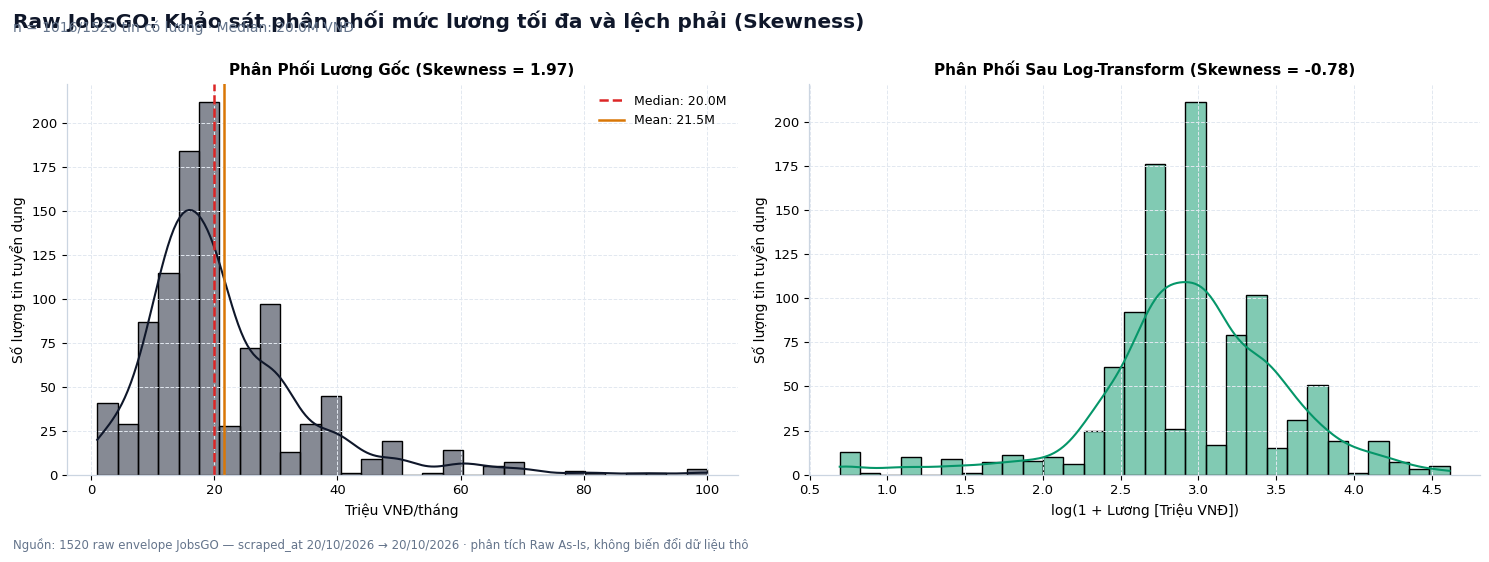

In [56]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. HÀM TIỀN XỬ LÝ LƯƠNG DÀNH RIÊNG CHO JOBSGO
# ==========================================
def extract_max_salary_jobsgo(salary_str):
    if pd.isna(salary_str):
        return np.nan
        
    val = str(salary_str).lower().strip()
    
    # Bỏ qua các tin thỏa thuận hoặc không có số liệu cụ thể
    null_salary_markers = ['thỏa thuận', 'thoả thuận', 'thương lượng', 'cạnh tranh', 'competitive', 'nego', 'đang cập nhật', 'đăng nhập']
    if any(marker in val for marker in null_salary_markers):
        return np.nan
        
    # Xử lý đơn vị USD nếu có
    is_usd = 'usd' in val or '$' in val
    
    val = val.replace(',', '.')
    nums = re.findall(r'\d+\.?\d*', val)
    
    if not nums:
        return np.nan
        
    nums = [float(n) for n in nums]
    max_val = max(nums)
    
    # Nếu là USD, quy đổi tạm thời ra Triệu VNĐ (tỷ giá ~25.000)
    if is_usd:
        max_val = (max_val * 25000) / 1_000_000
    elif max_val >= 1000:
        max_val = max_val / 1_000_000
        
    if max_val <= 0 or max_val > 500:
        return np.nan
        
    return max_val

# ==========================================
# 2. HÀM PHÂN TÍCH & TRỰC QUAN HÓA TỔNG HỢP (HIỂN THỊ + TỰ ĐỘNG LƯU)
# ==========================================
def analyze_and_plot_jobsgo_salary_v2(df_meta, df_top, save_filename="02_salary_distribution_skewness.png"):
    print("="*65)
    print("🔍 BẮT ĐẦU CHẨN ĐOÁN METADATA, GENERAL_INFO & LƯƠNG JOBSGO")
    print("="*65)
    
    # 2.1 Chẩn đoán Metadata
    if df_meta is not None and not df_meta.empty:
        print(f"✅ Metadata (`df_meta`): {len(df_meta)} bản ghi, {len(df_meta.columns)} cột.")
    
    # 2.2 Làm phẳng Payload
    if df_top is not None and not df_top.empty:
        payload_records = df_top.to_dict(orient='records')
        df_top_flat = pd.json_normalize(payload_records)
        print(f"✅ Raw Payload (`df_top`) đã làm phẳng: {len(df_top_flat)} bản ghi, {len(df_top_flat.columns)} cột.")
    else:
        print("❌ `df_top` trống hoặc không tồn tại.")
        return

    # 2.3 Quét cột lương thực tế trên JobsGO (ưu tiên salary_text, salary_raw, salary, general_info.salary)
    salary_cols = ['salary_text', 'salary_raw', 'salary', 'general_info.salary']
    target_salary_col = next((c for c in salary_cols if c in df_top_flat.columns and df_top_flat[c].notna().any()), None)
    
    if not target_salary_col:
        # Tìm cột có chứa chữ salary hoặc luong
        possible = [c for c in df_top_flat.columns if 'salary' in c.lower() or 'luong' in c.lower()]
        if possible:
            target_salary_col = possible[0]
            
    if not target_salary_col:
        print("⚠️ Không tìm thấy cột chứa chuỗi lương trong payload JobsGO.")
        return

    print(f"📌 Đã tìm thấy cột lương: [{target_salary_col}]")
    print(f"   Ví dụ giá trị thô: {df_top_flat[target_salary_col].dropna().head(3).tolist()}")

    # 2.4 Trích xuất mức lương
    salaries_millions = df_top_flat[target_salary_col].apply(extract_max_salary_jobsgo).dropna()
    print(f"📊 Bóc tách thành công: {len(salaries_millions)}/{len(df_top_flat)} tin có lương định lượng.")

    if salaries_millions.empty:
        print("⚠️ Tất cả tin tuyển dụng đều là 'Thỏa thuận' hoặc không có số liệu định lượng.")
        return

    # 2.5 Trực quan hóa
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.28)
    
    palette_colors = PALETTE if 'PALETTE' in globals() else ['#059669', '#e76f51', '#2563eb', '#d97706']
    warn_color = C_WARN if 'C_WARN' in globals() else '#dc2626'

    # Biểu đồ 1: Lương gốc
    sns.histplot(salaries_millions, kde=True, ax=axes[0], color=palette_colors[0], bins=30)
    median_val = salaries_millions.median()
    mean_val = salaries_millions.mean()
    skewness_val = salaries_millions.skew()
    
    axes[0].axvline(median_val, color=warn_color, linestyle="--", linewidth=1.8, label=f"Median: {median_val:.1f}M")
    axes[0].axvline(mean_val, color="#d97706", linestyle="-", linewidth=1.8, label=f"Mean: {mean_val:.1f}M")
    axes[0].set_title(f"Phân Phối Lương Gốc (Skewness = {skewness_val:.2f})", fontsize=11, fontweight='bold')
    axes[0].set_xlabel("Triệu VNĐ/tháng", fontsize=10)
    axes[0].set_ylabel("Số lượng tin tuyển dụng", fontsize=10)
    axes[0].legend(fontsize=9)
    
    # Biểu đồ 2: Log-Transformed
    log_salaries = np.log1p(salaries_millions)
    log_skewness = log_salaries.skew()
    
    sns.histplot(log_salaries, kde=True, ax=axes[1], color=palette_colors[1], bins=30)
    axes[1].set_title(f"Phân Phối Sau Log-Transform (Skewness = {log_skewness:.2f})", fontsize=11, fontweight='bold')
    axes[1].set_xlabel("log(1 + Lương [Triệu VNĐ])", fontsize=10)
    axes[1].set_ylabel("Số lượng tin tuyển dụng", fontsize=10)

    # 2.6 Lưu file tự động & Hiển thị trực tiếp ra Notebook
    source_lbl = SOURCE_LABEL if 'SOURCE_LABEL' in globals() else 'JobsGO'
    
    if 'finalize' in globals():
        finalize(fig, f"Raw {source_lbl}: Khảo sát phân phối mức lương tối đa và lệch phải (Skewness)",
                 f"n = {len(salaries_millions)}/{len(df_top_flat)} tin có lương · Median: {median_val:.1f}M VNĐ",
                 save_filename)
    else:
        out_dir = os.path.join("reports", "figures", "jobsgo")
        os.makedirs(out_dir, exist_ok=True)
        save_path = os.path.join(out_dir, save_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Đã lưu thành công biểu đồ tại: {save_path}")

# ==========================================
# THỰC THI PIPELINE
# ==========================================
analyze_and_plot_jobsgo_salary_v2(
    df_meta if 'df_meta' in globals() else None, 
    df_top if 'df_top' in globals() else None, 
    save_filename="02_salary_distribution_skewness.png"
)

# TRỤ CỘT 3: TÍNH DUY NHẤT VÀ TRÙNG LẶP

In [57]:
import pandas as pd
import numpy as np

def check_duplication_jobsgo(df_meta, df_top):
    """
    Hàm đo lường tỷ lệ trùng lặp dữ liệu theo 3 cấp độ cho JobsGO:
    1. Trùng lặp tuyệt đối & Trùng lặp khóa định danh / mã băm (tầng Metadata & Payload)
    2. Trùng lặp logic (Semantic duplicates qua Công ty + Tiêu đề + Địa điểm bên trong general_info)
    """
    print("--- TRỤ CỘT 3: CHẨN ĐOÁN TÍNH DUY NHẤT & TRÙNG LẶP (JOBSGO) ---")
    
    if df_top is None or df_top.empty:
        print("❌ `df_top` rỗng, không thể kiểm tra trùng lặp payload.")
        return

    # 1. Làm phẳng Payload để bóc tách các trường trong general_info (như company, location, title)
    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)
    total_records = len(df_top_flat)
    print(f"Tổng số bản ghi phân tích: {total_records}")

    # ==========================================
    # 1. TRÙNG LẶP TUYỆT ĐỐI & MÃ BĂM (METADATA & PAYLOAD)
    # ==========================================
    print("\n1. Trùng lặp mã định danh & Tầng vận hành (Metadata):")
    if df_meta is not None and not df_meta.empty:
        for col_meta in ['m_job_id', 'm_source_url', 'm_content_hash', 'm_canonical_hash']:
            if col_meta in df_meta.columns:
                dups = df_meta[col_meta].duplicated().sum()
                pct = (dups / len(df_meta)) * 100
                print(f"   - Cột [{col_meta}]: Trùng {dups} bản ghi ({pct:.2f}%)")
    else:
        print("   - ℹ️ Không có `df_meta` hoặc DataFrame trống.")

    # Trùng lặp tuyệt đối 100% trên payload đã làm phẳng
    df_string_format = df_top_flat.astype(str)
    exact_dups = df_string_format.duplicated().sum()
    exact_pct = (exact_dups / total_records) * 100
    print(f"\n   - Trùng lặp tuyệt đối 100% toàn bộ payload: {exact_dups} bản ghi ({exact_pct:.2f}%)")

    # ==========================================
    # 2. TRÙNG LẶP LOGIC (COMPANY + TITLE + LOCATION TRONG general_info)
    # ==========================================
    # Xác định các trường logic trên cấu trúc JobsGO (sau khi json_normalize)
    # Thông thường JobsGO có: 'company', 'title', 'location' hoặc các trường lồng trong general_info
    possible_comp = next((c for c in ['company', 'general_info.company', 'company_name'] if c in df_top_flat.columns), None)
    possible_title = next((c for c in ['title', 'general_info.title', 'job_title'] if c in df_top_flat.columns), None)
    possible_loc = next((c for c in ['location', 'general_info.location', 'company_address'] if c in df_top_flat.columns), None)

    logical_cols = [c for c in [possible_comp, possible_title, possible_loc] if c is not None]

    if len(logical_cols) >= 2:
        # Chuẩn hóa (lower-case & strip) để phát hiện HR đăng lại tin nhưng khác định dạng in hoa/thường
        temp_df = df_top_flat[logical_cols].fillna('').astype(str).apply(lambda x: x.str.lower().str.strip())
        logical_dups = temp_df.duplicated().sum()
        logical_pct = (logical_dups / total_records) * 100
        
        print(f"\n2. Trùng lặp logic (Theo các trường: {logical_cols}):")
        print(f"   - Số lượng cụm/tin trùng: {logical_dups} bản ghi")
        print(f"   - Tỷ lệ: {logical_pct:.2f}%")
    else:
        logical_dups = 0
        print(f"\n2. Trùng lặp logic: Không đủ các cột định danh doanh nghiệp, tiêu đề và địa điểm trong payload.")

    # ==========================================
    # KẾT LUẬN & ĐỀ XUẤT PRE-PROCESSING
    # ==========================================
    print("\n" + "="*50)
    max_dups = max(exact_dups, logical_dups)
    if max_dups > 0:
        print("⚠️ CHẨN ĐOÁN: Dữ liệu JobsGO chứa bản ghi trùng lặp (Overlapping / Repost).")
        print("💡 HƯỚNG XỬ LÝ (Pre-processing):")
        print("   -> Bước 1: Lọc trùng dựa trên khóa `m_content_hash` hoặc `m_source_url` trong `df_meta` để loại bỏ tin cào lặp.")
        if logical_cols:
            print(f"   -> Bước 2: Gọi drop_duplicates(subset={logical_cols}) và ưu tiên giữ lại tin mới nhất (dựa trên `general_info.posted_date`) để xử lý tin tuyển dụng đăng lại.")
    else:
        print("✅ TUYỆT VỜI: Không phát hiện bản ghi trùng lặp logic nào trên payload.")

# ==========================================
# THỰC THI PIPELINE CHẨN ĐOÁN TRÙNG LẶP CHO JOBSGO
# ==========================================
check_duplication_jobsgo(
    df_meta if 'df_meta' in globals() else None, 
    df_top if 'df_top' in globals() else None
)

--- TRỤ CỘT 3: CHẨN ĐOÁN TÍNH DUY NHẤT & TRÙNG LẶP (JOBSGO) ---
Tổng số bản ghi phân tích: 1520

1. Trùng lặp mã định danh & Tầng vận hành (Metadata):
   - Cột [m_job_id]: Trùng 0 bản ghi (0.00%)
   - Cột [m_source_url]: Trùng 0 bản ghi (0.00%)
   - Cột [m_content_hash]: Trùng 0 bản ghi (0.00%)

   - Trùng lặp tuyệt đối 100% toàn bộ payload: 1 bản ghi (0.07%)

2. Trùng lặp logic (Theo các trường: ['company', 'title', 'location']):
   - Số lượng cụm/tin trùng: 178 bản ghi
   - Tỷ lệ: 11.71%

⚠️ CHẨN ĐOÁN: Dữ liệu JobsGO chứa bản ghi trùng lặp (Overlapping / Repost).
💡 HƯỚNG XỬ LÝ (Pre-processing):
   -> Bước 1: Lọc trùng dựa trên khóa `m_content_hash` hoặc `m_source_url` trong `df_meta` để loại bỏ tin cào lặp.
   -> Bước 2: Gọi drop_duplicates(subset=['company', 'title', 'location']) và ưu tiên giữ lại tin mới nhất (dựa trên `general_info.posted_date`) để xử lý tin tuyển dụng đăng lại.


# TRỤ CỘT 5: BIAS AND BALANCE PROFILING

--- TRỤ CỘT 5: CHẨN ĐOÁN THIÊN LỆCH & MẤT CÂN BẰNG (JOBSGO) ---
Tổng số bản ghi phân tích: 1520

1. Phân bổ Cấp bậc (Seniority) [general_info.job_level]:
 - Nhân Viên/Chuyên Viên: 1232 tin (81.1%)
 - Thực Tập Sinh: 163 tin (10.7%)
 - Trưởng Nhóm/Trưởng Phòng: 114 tin (7.5%)
 - : 8 tin (0.5%)
 - Giám Đốc Và Cấp Cao Hơn: 3 tin (0.2%)
 => Imbalance Ratio (Max/Min): 410.7x

2. Phân bổ Địa lý (Location) [location]:
 - Hồ Chí Minh: 645 tin (42.4%)
 - Hà Nội: 531 tin (34.9%)
 - Đồng Nai: 84 tin (5.5%)
 - Đà Nẵng: 24 tin (1.6%)
 - Bình Dương: 23 tin (1.5%)

3. Chẩn đoán Kỹ năng (Quy luật Pareto) [requirements_bullets]:
 - Tổng số tags/bullets xuất hiện: 1070
 - Số lượng kỹ năng duy nhất (Unique): 533
 - Nhóm Top 319 kỹ năng (chiếm 59.8% unique) chi phối 80% thị trường.
🖼️  Đã lưu reports\figures\jobsgo\03_skills_pareto_distribution.png (DPI 300)


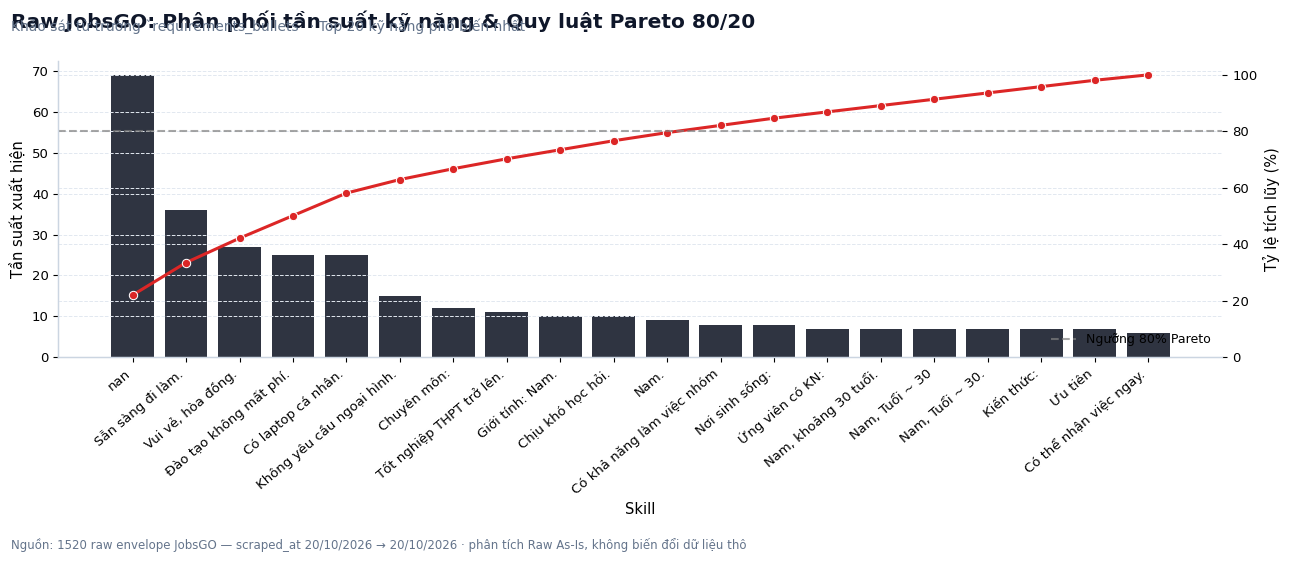

🖼️  Đã lưu reports\figures\jobsgo\04_bias_and_class_balance.png (DPI 300)


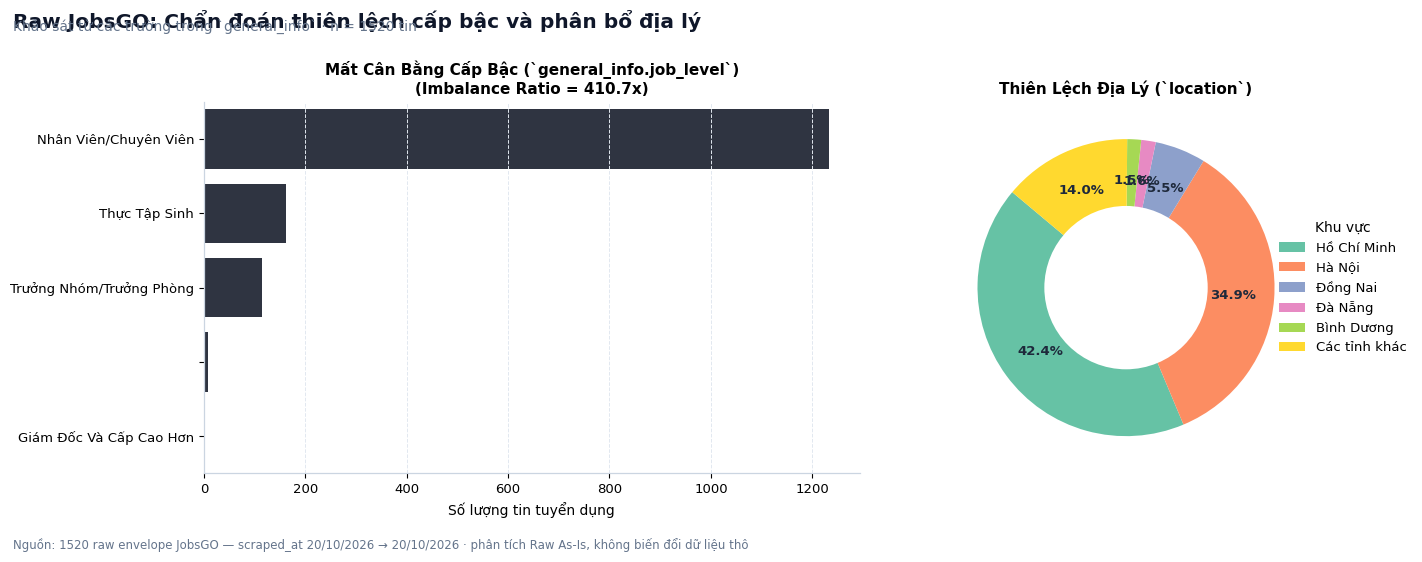

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. HÀM ĐÁNH GIÁ CHỈ SỐ MẤT CÂN BẰNG (TEXT REPORT - METADATA & PAYLOAD)
# ==========================================
def profile_bias_and_balance_jobsgo(df_meta, df_top):
    print("--- TRỤ CỘT 5: CHẨN ĐOÁN THIÊN LỆCH & MẤT CÂN BẰNG (JOBSGO) ---")
    
    if df_top is None or df_top.empty:
        print("❌ `df_top` trống hoặc không tồn tại.")
        return

    # Làm phẳng Raw Payload để lấy các trường lồng nhau trong general_info
    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)
    total_records = len(df_top_flat)
    print(f"Tổng số bản ghi phân tích: {total_records}")

    # 1. Mất cân bằng Cấp bậc (Seniority Bias) trong general_info.job_level
    level_col = next((c for c in ['general_info.job_level', 'job_level', 'level'] if c in df_top_flat.columns), None)
    if level_col:
        print(f"\n1. Phân bổ Cấp bậc (Seniority) [{level_col}]:")
        seniority_counts = df_top_flat[level_col].value_counts()
        for level, count in seniority_counts.items():
            pct = (count / total_records) * 100
            print(f" - {level}: {count} tin ({pct:.1f}%)")
        if len(seniority_counts) >= 2 and seniority_counts.min() > 0:
            imbalance_ratio = seniority_counts.max() / seniority_counts.min()
            print(f" => Imbalance Ratio (Max/Min): {imbalance_ratio:.1f}x")

    # 2. Thiên lệch Địa lý (Geographic Bias)
    loc_col = next((c for c in ['location', 'general_info.location', 'company_address'] if c in df_top_flat.columns), None)
    if loc_col:
        print(f"\n2. Phân bổ Địa lý (Location) [{loc_col}]:")
        geo_counts = df_top_flat[loc_col].value_counts().head(5)
        for loc, count in geo_counts.items():
            pct = (count / total_records) * 100
            print(f" - {loc}: {count} tin ({pct:.1f}%)")

    # 3. Tính Thưa thớt Kỹ năng (Skill Sparsity - Pareto 80/20)
    skill_col = next((c for c in ['keywords', 'skills', 'requirements_bullets'] if c in df_top_flat.columns), None)
    if skill_col:
        all_skills = df_top_flat[skill_col].dropna().explode().astype(str).str.strip()
        valid_skills = all_skills[all_skills.str.len() <= 25]
        skill_counts = valid_skills.value_counts()
        total_skill_tags = len(valid_skills)
        unique_skills = len(skill_counts)

        if total_skill_tags > 0:
            cumulative_pct = (skill_counts.cumsum() / total_skill_tags) * 100
            top_skills_for_80_pct = cumulative_pct[cumulative_pct <= 80].count()
            pareto_ratio = (top_skills_for_80_pct / unique_skills) * 100 if unique_skills > 0 else 0
            print(f"\n3. Chẩn đoán Kỹ năng (Quy luật Pareto) [{skill_col}]:")
            print(f" - Tổng số tags/bullets xuất hiện: {total_skill_tags}")
            print(f" - Số lượng kỹ năng duy nhất (Unique): {unique_skills}")
            print(f" - Nhóm Top {top_skills_for_80_pct} kỹ năng (chiếm {pareto_ratio:.1f}% unique) chi phối 80% thị trường.")

# ==========================================
# 2. HÀM VẼ BIỂU ĐỒ PARETO KỸ NĂNG (JOBSGO)
# ==========================================
def plot_skills_pareto_jobsgo(df_top, save_filename="03_skills_pareto_distribution.png"):
    if df_top is None or df_top.empty:
        return

    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)

    skill_col = next((c for c in ['keywords', 'skills', 'requirements_bullets'] if c in df_top_flat.columns), None)
    if not skill_col:
        print("⚠️ Không tìm thấy cột kỹ năng/keywords để vẽ biểu đồ Pareto.")
        return

    all_skills = df_top_flat[skill_col].dropna().explode().astype(str).str.strip()
    valid_skills = all_skills[(all_skills.str.len() <= 25) & (all_skills.str.len() > 1)]
    
    top20 = valid_skills.value_counts().head(20).reset_index()
    top20.columns = ["Skill", "Frequency"]
    if top20.empty:
        return

    top20["Cum_Percent"] = (top20["Frequency"].cumsum() / top20["Frequency"].sum()) * 100

    fig, ax1 = plt.subplots(figsize=(13, 5.5))
    ax2 = ax1.twinx()

    palette_colors = PALETTE if 'PALETTE' in globals() else ['#059669', '#e76f51', '#2563eb', '#d97706']
    warn_color = C_WARN if 'C_WARN' in globals() else '#dc2626'

    sns.barplot(data=top20, x="Skill", y="Frequency", ax=ax1, color=palette_colors[0], alpha=0.88)
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=40, ha="right", fontsize=9.5)
    ax1.set_ylabel("Tần suất xuất hiện", fontsize=10.5)

    sns.lineplot(data=top20, x="Skill", y="Cum_Percent", ax=ax2, color=warn_color, marker="o", linewidth=2.2)
    ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng 80% Pareto")
    ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=10.5)
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right", fontsize=9)

    source_lbl = SOURCE_LABEL if 'SOURCE_LABEL' in globals() else 'JobsGO'
    
    if 'finalize' in globals():
        finalize(fig, f"Raw {source_lbl}: Phân phối tần suất kỹ năng & Quy luật Pareto 80/20",
                 f"Khảo sát từ trường `{skill_col}` · Top 20 kỹ năng phổ biến nhất",
                 save_filename)
    else:
        out_dir = os.path.join("reports", "figures", "jobsgo")
        os.makedirs(out_dir, exist_ok=True)
        save_path = os.path.join(out_dir, save_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Đã lưu Biểu đồ Pareto Kỹ năng tại: {save_path}")

# ==========================================
# 3. HÀM VẼ BIỂU ĐỒ MẤT CÂN BẰNG LỚP & ĐỊA LÝ (JOBSGO)
# ==========================================
def plot_bias_and_balance_jobsgo(df_top, save_filename="04_bias_and_class_balance.png"):
    if df_top is None or df_top.empty:
        return

    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.3)

    palette_colors = PALETTE if 'PALETTE' in globals() else ['#059669', '#e76f51', '#2563eb', '#d97706']

    # 3.1 Biểu đồ Cấp bậc (general_info.job_level)
    level_col = next((c for c in ['general_info.job_level', 'job_level', 'level'] if c in df_top_flat.columns), None)
    if level_col:
        seniority_counts = df_top_flat[level_col].value_counts()
        sns.barplot(x=seniority_counts.values, y=seniority_counts.index, ax=axes[0], color=palette_colors[0], alpha=0.88)
        imbalance_ratio = seniority_counts.max() / seniority_counts.min() if (len(seniority_counts) >= 2 and seniority_counts.min() > 0) else 1
        axes[0].set_title(f"Mất Cân Bằng Cấp Bậc (`{level_col}`)\n(Imbalance Ratio = {imbalance_ratio:.1f}x)", fontsize=11, fontweight='bold')
        axes[0].set_xlabel("Số lượng tin tuyển dụng", fontsize=10)
        axes[0].set_ylabel("")
    else:
        axes[0].text(0.5, 0.5, "Không tìm thấy trường Cấp bậc", ha="center", va="center")

    loc_col = next((c for c in ['location', 'general_info.location', 'company_address'] if c in df_top_flat.columns), None)
    if loc_col:
        top_loc = df_top_flat[loc_col].value_counts().head(5)
        if len(df_top_flat[loc_col].value_counts()) > 5:
            other_count = df_top_flat[loc_col].value_counts().iloc[5:].sum()
            top_loc['Các tỉnh khác'] = other_count
            
        # Không dùng labels trực tiếp trong pie mà dùng legend riêng biệt
        wedges, texts, autotexts = axes[1].pie(
            top_loc, 
            autopct="%1.1f%%", 
            startangle=140,
            colors=sns.color_palette("Set2", len(top_loc)), 
            pctdistance=0.72,
            textprops={'fontsize': 9.5, 'weight': 'bold', 'color': '#1e293b'}
        )
        
        # Tạo lỗ trống ở giữa để biến thành Donut Chart
        centre_circle = plt.Circle((0,0), 0.55, fc='white')
        axes[1].add_artist(centre_circle)
        
        # Thêm Legend chú thích sang bên phải, loại bỏ hoàn toàn hiện tượng chồng chéo chữ
        axes[1].legend(
            wedges, top_loc.index,
            title="Khu vực",
            loc="center left",
            bbox_to_anchor=(0.88, 0, 0.5, 1),
            fontsize=9.5
        )
        axes[1].set_title(f"Thiên Lệch Địa Lý (`{loc_col}`)", fontsize=11, fontweight='bold')
    else:
        axes[1].text(0.5, 0.5, "Không tìm thấy trường Địa lý", ha="center", va="center")

    source_lbl = SOURCE_LABEL if 'SOURCE_LABEL' in globals() else 'JobsGO'

    if 'finalize' in globals():
        finalize(fig, f"Raw {source_lbl}: Chẩn đoán thiên lệch cấp bậc và phân bổ địa lý",
                 f"Khảo sát từ các trường trong `general_info` · n = {len(df_top_flat)} tin",
                 save_filename)
    else:
        out_dir = os.path.join("reports", "figures", "jobsgo")
        os.makedirs(out_dir, exist_ok=True)
        save_path = os.path.join(out_dir, save_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Đã lưu Biểu đồ Bias & Balance tại: {save_path}")

# ==========================================
# THỰC THI PIPELINE
# ==========================================
# 1. In báo cáo text
profile_bias_and_balance_jobsgo(
    df_meta if 'df_meta' in globals() else None, 
    df_top if 'df_top' in globals() else None
)

# 2. Vẽ và lưu trực tiếp biểu đồ
plot_skills_pareto_jobsgo(
    df_top if 'df_top' in globals() else None, 
    save_filename="03_skills_pareto_distribution.png"
)

plot_bias_and_balance_jobsgo(
    df_top if 'df_top' in globals() else None, 
    save_filename="04_bias_and_class_balance.png"
)

HEAT MAP

--- TRỤ CỘT 4: CHẨN ĐOÁN MA TRẬN TƯƠNG QUAN SPEARMAN (JOBSGO) ---
 💰 Đang trích xuất Lương Min/Max từ cột [salary_raw]...
 ⏳ Đang trích xuất Số năm kinh nghiệm từ cột [experience]...
 📝 Đang tính toán độ dài văn bản JD từ các mảng bullets...
🖼️  Đã lưu reports\figures\jobsgo\05_spearman_correlation_matrix.png (DPI 300)


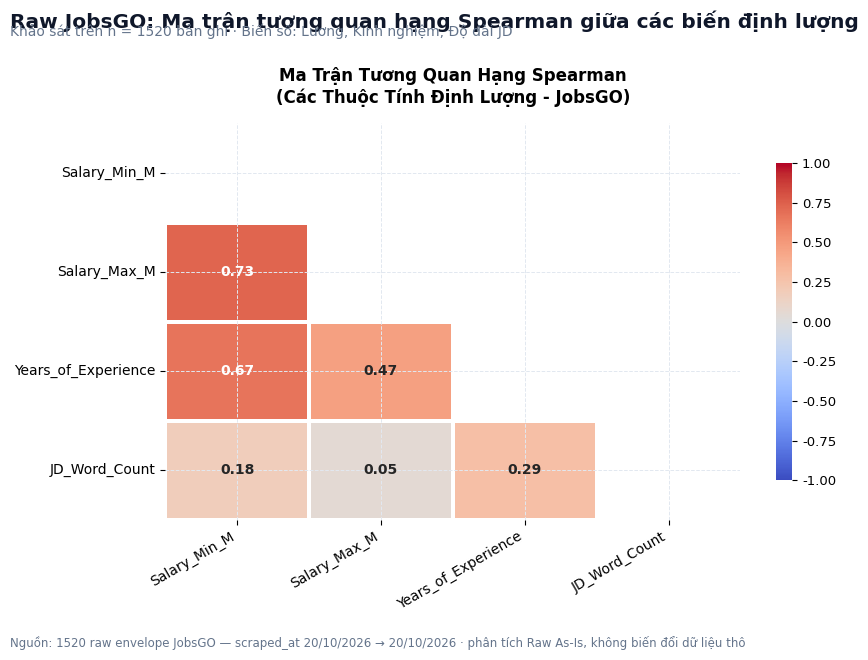

,Salary_Min_M,Salary_Max_M,Years_of_Experience,JD_Word_Count
Salary_Min_M,1.000000,0.727694,0.671426,0.177920
Salary_Max_M,0.727694,1.000000,0.465722,0.048039
Years_of_Experience,0.671426,0.465722,1.000000,0.286683
JD_Word_Count,0.177920,0.048039,0.286683,1.000000


In [61]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. HÀM TIỀN XỬ LÝ ĐẶC TRƯNG SỐ HỌC (JOBSGO)
# ==========================================
def extract_salary_min_max_jobsgo(salary_str):
    """
    Bóc tách lương Min và Max từ chuỗi trên JobsGO (hỗ trợ VND/USD)
    """
    if pd.isna(salary_str):
        return np.nan, np.nan
        
    s = str(salary_str).lower().strip()
    null_markers = ['thỏa thuận', 'thoả thuận', 'thương lượng', 'cạnh tranh', 'competitive', 'nego', 'đang cập nhật', 'đăng nhập']
    if any(m in s for m in null_markers):
        return np.nan, np.nan
        
    is_usd = 'usd' in s or '$' in s
    s = s.replace(',', '.')
    nums = [float(n) for n in re.findall(r'\d+\.?\d*', s)]
    
    if not nums:
        return np.nan, np.nan
        
    # Quy đổi USD sang Triệu VNĐ (~25.000) hoặc chuẩn hóa số nguyên lớn
    if is_usd:
        nums = [(n * 25000) / 1_000_000 for n in nums]
    else:
        nums = [n / 1_000_000 if n >= 1000 else n for n in nums]
    
    # Lọc bỏ ngoại lai không hợp lý
    nums = [n for n in nums if 0 < n <= 500]
    if not nums:
        return np.nan, np.nan
        
    if len(nums) >= 2:
        return min(nums), max(nums)
    elif len(nums) == 1:
        if 'lên đến' in s or 'tới' in s or 'tối đa' in s:
            return np.nan, nums[0]
        elif 'từ' in s or 'trên' in s or 'tối thiểu' in s:
            return nums[0], np.nan
        return nums[0], nums[0]
    return np.nan, np.nan

def extract_experience_years_jobsgo(exp_str):
    """
    Bóc tách số năm kinh nghiệm từ chuỗi (ví dụ: '1 năm', 'Dưới 2 năm')
    """
    if pd.isna(exp_str):
        return np.nan
    s = str(exp_str).lower()
    if 'chưa' in s or 'không' in s or 'không yêu cầu' in s:
        return 0.0
    nums = re.findall(r'\d+', s)
    return float(nums[0]) if nums else np.nan

# ==========================================
# 2. HÀM VẼ MA TRẬN TƯƠNG QUAN SPEARMAN (JOBSGO)
# ==========================================
def plot_correlation_heatmap_jobsgo(df_meta, df_top, save_filename="05_spearman_correlation_matrix.png"):
    print("--- TRỤ CỘT 4: CHẨN ĐOÁN MA TRẬN TƯƠNG QUAN SPEARMAN (JOBSGO) ---")
    
    if df_top is None or df_top.empty:
        print("❌ `df_top` trống hoặc không tồn tại.")
        return None

    # Làm phẳng Payload để lấy các trường trong general_info và mảng bullets
    payload_records = df_top.to_dict(orient='records')
    df_top_flat = pd.json_normalize(payload_records)
    
    df_num = pd.DataFrame()
    
    # 2.1 Trích xuất Lương từ các nguồn tiềm năng
    salary_col = next((c for c in ['salary_text', 'salary_raw', 'salary', 'general_info.salary'] if c in df_top_flat.columns and df_top_flat[c].notna().any()), None)
    if salary_col:
        print(f" 💰 Đang trích xuất Lương Min/Max từ cột [{salary_col}]...")
        salary_tuples = df_top_flat[salary_col].apply(extract_salary_min_max_jobsgo)
        df_num['Salary_Min_M'] = salary_tuples.apply(lambda x: x[0])
        df_num['Salary_Max_M'] = salary_tuples.apply(lambda x: x[1])

    # 2.2 Trích xuất Kinh nghiệm từ general_info (hoặc các trường tương đương)
    exp_col = next((c for c in ['general_info.experience', 'experience', 'exp'] if c in df_top_flat.columns), None)
    if exp_col:
        print(f" ⏳ Đang trích xuất Số năm kinh nghiệm từ cột [{exp_col}]...")
        df_num['Years_of_Experience'] = df_top_flat[exp_col].apply(extract_experience_years_jobsgo)

    # 2.3 Đếm số lượng từ khóa / kỹ năng
    skill_col = next((c for c in ['keywords', 'skills'] if c in df_top_flat.columns), None)
    if skill_col:
        print(" 🏷️ Đang đếm số lượng Tags kỹ năng...")
        df_num['Total_Skills_Count'] = df_top_flat[skill_col].apply(
            lambda x: len(x) if isinstance(x, list) else 0
        )

    # 2.4 Tính toán độ dài văn bản JD (từ description_bullets, requirements_bullets, benefits_bullets)
    print(" 📝 Đang tính toán độ dài văn bản JD từ các mảng bullets...")
    def count_words_in_bullets(lst):
        if not isinstance(lst, list): return 0
        return sum(len(str(item).split()) for item in lst)

    desc_len = df_top_flat['description_bullets'].apply(count_words_in_bullets) if 'description_bullets' in df_top_flat.columns else 0
    req_len = df_top_flat['requirements_bullets'].apply(count_words_in_bullets) if 'requirements_bullets' in df_top_flat.columns else 0
    ben_len = df_top_flat['benefits_bullets'].apply(count_words_in_bullets) if 'benefits_bullets' in df_top_flat.columns else 0
    
    df_num['JD_Word_Count'] = desc_len + req_len + ben_len

    # Loại bỏ các cột hoàn toàn NaN
    df_num = df_num.dropna(how='all', axis=1)
    
    if df_num.empty or df_num.shape[1] < 2:
        print("❌ Không đủ các biến số học hợp lệ để tính toán ma trận tương quan.")
        return None

    # 2.5 Tính toán ma trận tương quan Spearman
    corr_matrix = df_num.corr(method="spearman")
    
    if corr_matrix.isna().all().all():
        print("❌ Ma trận tương quan toàn giá trị NaN.")
        return None

    # 2.6 Vẽ Heatmap
    fig, ax = plt.subplots(figsize=(9, 6.5))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    palette_cmap = "coolwarm"
    sns.heatmap(
        corr_matrix, 
        mask=mask, 
        annot=True,          
        fmt=".2f",           
        cmap=palette_cmap,     
        vmin=-1, vmax=1,     
        linewidths=1.5, 
        cbar_kws={"shrink": 0.8},
        annot_kws={"size": 10, "weight": "bold"},
        ax=ax
    )
    
    ax.set_title("Ma Trận Tương Quan Hạng Spearman\n(Các Thuộc Tính Định Lượng - JobsGO)", 
                 fontsize=12, fontweight='bold', pad=15)
    
    plt.xticks(rotation=30, ha='right', fontsize=10)
    plt.yticks(rotation=0, fontsize=10)
    
    source_lbl = SOURCE_LABEL if 'SOURCE_LABEL' in globals() else 'JobsGO'

    if 'finalize' in globals():
        finalize(fig, f"Raw {source_lbl}: Ma trận tương quan hạng Spearman giữa các biến định lượng",
                 f"Khảo sát trên n = {len(df_top_flat)} bản ghi · Biến số: Lương, Kinh nghiệm, Độ dài JD",
                 save_filename)
    else:
        out_dir = os.path.join("reports", "figures", "jobsgo")
        os.makedirs(out_dir, exist_ok=True)
        save_path = os.path.join(out_dir, save_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"✅ Đã lưu Heatmap tương quan tại: {save_path}")
        
    return corr_matrix

# ==========================================
# THỰC THI PIPELINE TƯƠNG QUAN CHO JOBSGO
# ==========================================
correlation_table = plot_correlation_heatmap_jobsgo(
    df_meta if 'df_meta' in globals() else None, 
    df_top if 'df_top' in globals() else None, 
    save_filename="05_spearman_correlation_matrix.png"
)

if correlation_table is not None:
    display(correlation_table)